In [74]:
import os
import json
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    BatchNormalization,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

sns.set_style("whitegrid")

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

In [75]:
PROJECT_DIR = Path("..")

DATA_DIR = PROJECT_DIR / "data"

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

MODEL_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

IMAGE_SIZE = (224,224)

BATCH_SIZE = 32

EPOCHS = 10

LEARNING_RATE = 1e-4

## Dataset Loading

Images are resized to **224 × 224**.

Training images are augmented to improve generalization.

Validation and test images are only preprocessed.

In [76]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

In [77]:
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

Found 2499 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [78]:
print("Classes")

print(train_generator.class_indices)

print()

print("Training Images :", train_generator.samples)

print("Validation Images :", val_generator.samples)

print("Testing Images :", test_generator.samples)

Classes
{'NORMAL': 0, 'PNEUMONIA': 1}

Training Images : 2499
Validation Images : 16
Testing Images : 624


## Data Augmentation

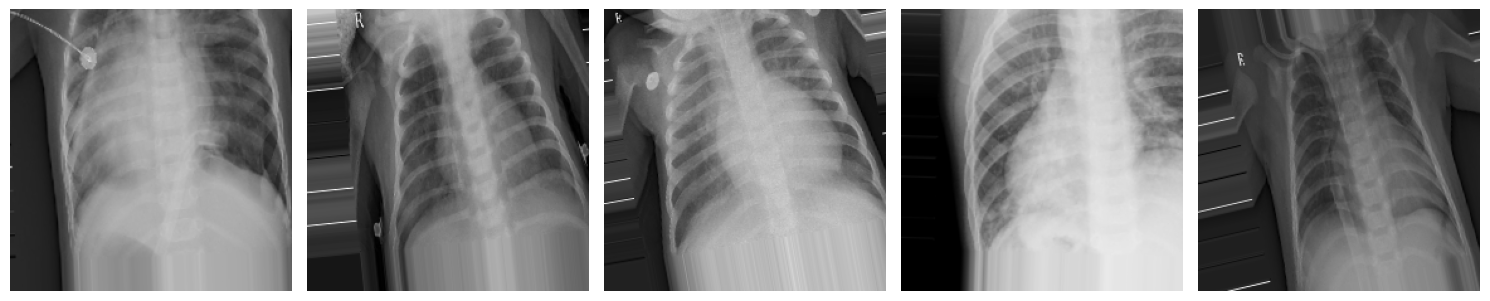

In [79]:
images, labels = next(train_generator)

plt.figure(figsize=(15,5))

for i in range(5):

    plt.subplot(1,5,i+1)

    img = (images[i]+1)/2

    plt.imshow(np.clip(img,0,1))

    plt.axis("off")

plt.tight_layout()

plt.show()

## MobileNetV2

MobileNetV2 is used as the feature extractor.

The pretrained ImageNet weights are retained while the classifier is replaced with a custom binary classifier.

In [80]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    BatchNormalization(),
    Dense(
        128,
        activation="relu"
    ),

    Dropout(0.5),
    Dense(
        1,
        activation="sigmoid"
    )
])

In [81]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,427,201 (9.26 MB)

 Trainable params: 166,657 (651.00 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

## Compile Model

The model is compiled using:

- Adam Optimizer
- Binary Crossentropy Loss
- Accuracy
- Precision
- Recall

In [82]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),

    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

## Training Callbacks

In [83]:
checkpoint = ModelCheckpoint(
    filepath=MODEL_DIR/"checkpoint_best.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# Model Training

Only the classifier head is trained while the MobileNetV2 feature extractor remains frozen.

In [84]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=[
        checkpoint,
        early_stop,
        reduce_lr
    ]
)

Epoch 1/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 499ms/step - accuracy: 0.6932 - loss: 0.6296 - precision: 0.8192 - recall: 0.7369
Epoch 1: val_loss improved from None to 0.49867, saving model to ..\models\checkpoint_best.keras
79/79 ━━━━━━━━━━━━━━━━━━━━ 44s 519ms/step - accuracy: 0.7735 - loss: 0.4783 - precision: 0.8811 - recall: 0.7944 - val_accuracy: 0.6875 - val_loss: 0.4987 - val_precision: 0.6364 - val_recall: 0.8750 - learning_rate: 1.0000e-04
Epoch 2/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 476ms/step - accuracy: 0.8638 - loss: 0.3219 - precision: 0.9224 - recall: 0.8867
Epoch 2: val_loss improved from 0.49867 to 0.36018, saving model to ..\models\checkpoint_best.keras
79/79 ━━━━━━━━━━━━━━━━━━━━ 38s 482ms/step - accuracy: 0.8752 - loss: 0.2989 - precision: 0.9280 - recall: 0.8972 - val_accuracy: 0.9375 - val_loss: 0.3602 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 1.0000e-04
Epoch 3/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 475ms/step - accuracy: 0.9036 - loss: 0.2434 - precision: 0.

In [85]:
with open(RESULTS_DIR/"history.json","w") as f:

    json.dump(history.history,f)

# Model Evaluation

The best model saved during training is evaluated on the unseen test dataset.

Evaluation metrics include:

- Accuracy
- Precision
- Recall
- F1 Score
- Confusion Matrix
- ROC Curve
- Precision-Recall Curve

In [86]:
best_model = tf.keras.models.load_model(
    MODEL_DIR / "checkpoint_best.keras"
)

print("✅ Best checkpoint loaded successfully.")

✅ Best checkpoint loaded successfully.


In [87]:
test_loss, test_accuracy, test_precision, test_recall = best_model.evaluate(
    test_generator,
    verbose=1
)

print(f"Test Loss      : {test_loss:.4f}")
print(f"Test Accuracy  : {test_accuracy:.4f}")
print(f"Test Precision : {test_precision:.4f}")
print(f"Test Recall    : {test_recall:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 303ms/step - accuracy: 0.8894 - loss: 0.2395 - precision: 0.8724 - recall: 0.9641
Test Loss      : 0.2395
Test Accuracy  : 0.8894
Test Precision : 0.8724
Test Recall    : 0.9641


In [88]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

probabilities = best_model.predict(test_generator)

predictions = (probabilities > 0.5).astype(int).flatten()

true_labels = test_generator.classes

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 312ms/step


In [89]:
accuracy = accuracy_score(true_labels, predictions)

precision = precision_score(true_labels, predictions)

recall = recall_score(true_labels, predictions)

f1 = f1_score(true_labels, predictions)

roc_auc = auc(
    *roc_curve(true_labels, probabilities)[:2]
)

average_precision = average_precision_score(
    true_labels,
    probabilities
)

In [90]:
metrics_df = pd.DataFrame({

    "Metric":[

        "Accuracy",

        "Precision",

        "Recall",

        "F1 Score",

        "ROC AUC",

        "Average Precision"

    ],

    "Score":[

        accuracy,

        precision,

        recall,

        f1,

        roc_auc,

        average_precision

    ]

})

metrics_df

,Metric,Score
0,Accuracy,0.889423
1,Precision,0.872390
2,Recall,0.964103
3,F1 Score,0.915956
4,ROC AUC,0.967445
5,Average Precision,0.978969


In [91]:
metrics_df.to_csv(
    RESULTS_DIR / "metrics.csv",
    index=False
)

metrics = metrics_df.set_index(
    "Metric"
)["Score"].to_dict()

with open(
    RESULTS_DIR / "metrics.json",
    "w"
) as f:

    json.dump(metrics, f, indent=4)

In [92]:
report = classification_report(

    true_labels,

    predictions,

    target_names=[
        "Normal",
        "Pneumonia"
    ]

)

print(report)

              precision    recall  f1-score   support

      Normal       0.93      0.76      0.84       234
   Pneumonia       0.87      0.96      0.92       390

    accuracy                           0.89       624
   macro avg       0.90      0.86      0.88       624
weighted avg       0.89      0.89      0.89       624



In [93]:
with open(
    RESULTS_DIR / "classification_report.txt",
    "w"
) as f:

    f.write(report)

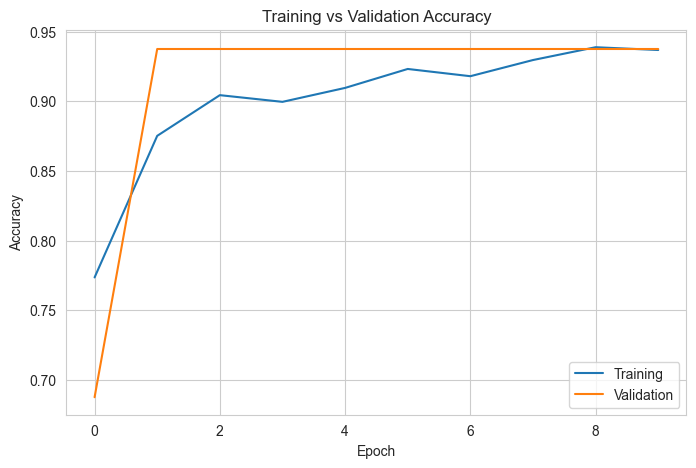

In [94]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history["accuracy"],
    label="Training"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.title("Training vs Validation Accuracy")

plt.legend()

plt.grid(True)
'''
plt.savefig(
    RESULTS_DIR / "accuracy_curve.png",
    dpi=300,
    bbox_inches="tight"
) '''

plt.show()

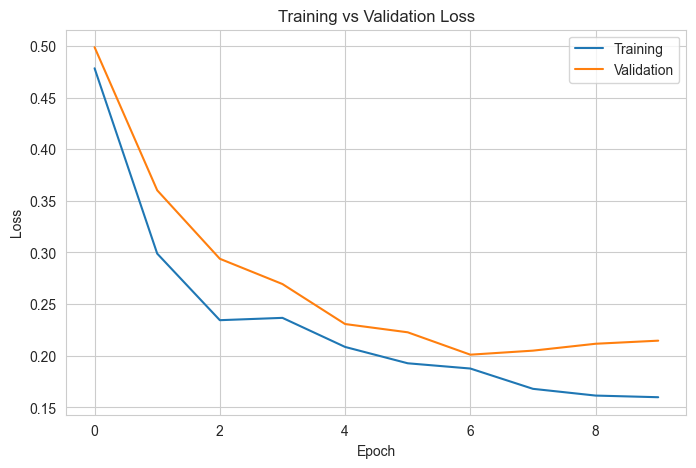

In [95]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history["loss"],
    label="Training"
)

plt.plot(
    history.history["val_loss"],
    label="Validation"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Training vs Validation Loss")

plt.legend()

plt.grid(True)
'''
plt.savefig(
    RESULTS_DIR / "loss_curve.png",
    dpi=300,
    bbox_inches="tight"
) '''

plt.show()

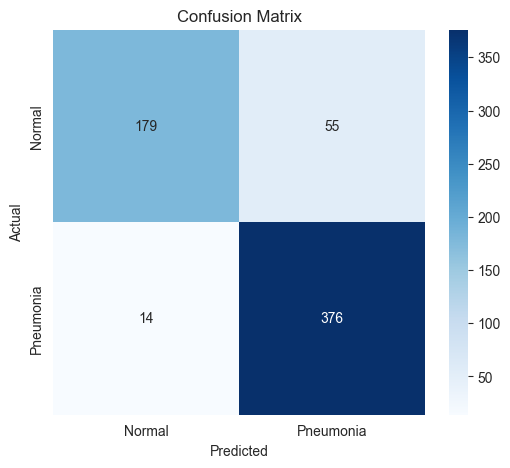

In [96]:
cm = confusion_matrix(
    true_labels,
    predictions
)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=[
        "Normal",
        "Pneumonia"
    ],

    yticklabels=[
        "Normal",
        "Pneumonia"
    ]

)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

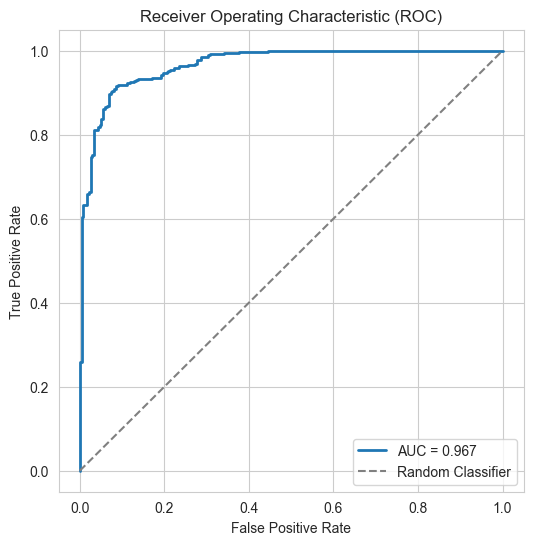

In [97]:
from sklearn.metrics import roc_curve, auc

# Calculate ROC values
fpr, tpr, _ = roc_curve(true_labels, probabilities)

roc_auc = auc(fpr, tpr)

# Plot ROC Curve
plt.figure(figsize=(6,6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {roc_auc:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC)")
plt.legend(loc="lower right")
plt.grid(True)

plt.savefig(
    RESULTS_DIR / "roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

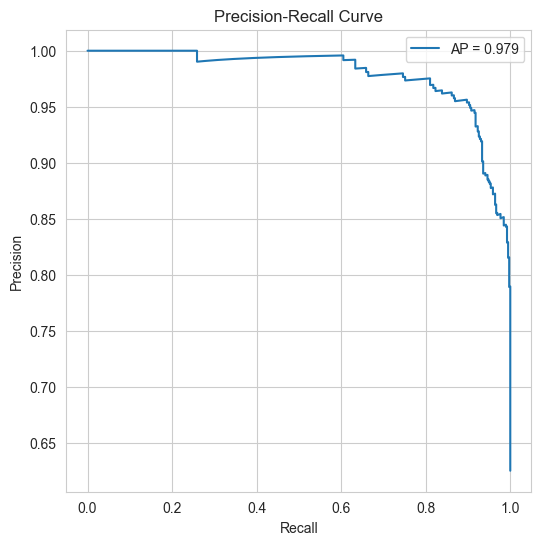

In [98]:
precision_curve, recall_curve, _ = precision_recall_curve(
    true_labels,
    probabilities
)

plt.figure(figsize=(6,6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"AP = {average_precision:.3f}"
)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title("Precision-Recall Curve")

plt.legend()

plt.grid(True)

plt.show()

# Error Analysis

Understanding where the model makes mistakes is as important as measuring its overall accuracy.

In this section, misclassified Chest X-ray images are visualized along with their predicted labels and confidence scores.

In [99]:
from tensorflow.keras.preprocessing import image

misclassified = np.where(predictions != true_labels)[0]

print(f"Total Misclassified Images : {len(misclassified)}")

Total Misclassified Images : 69


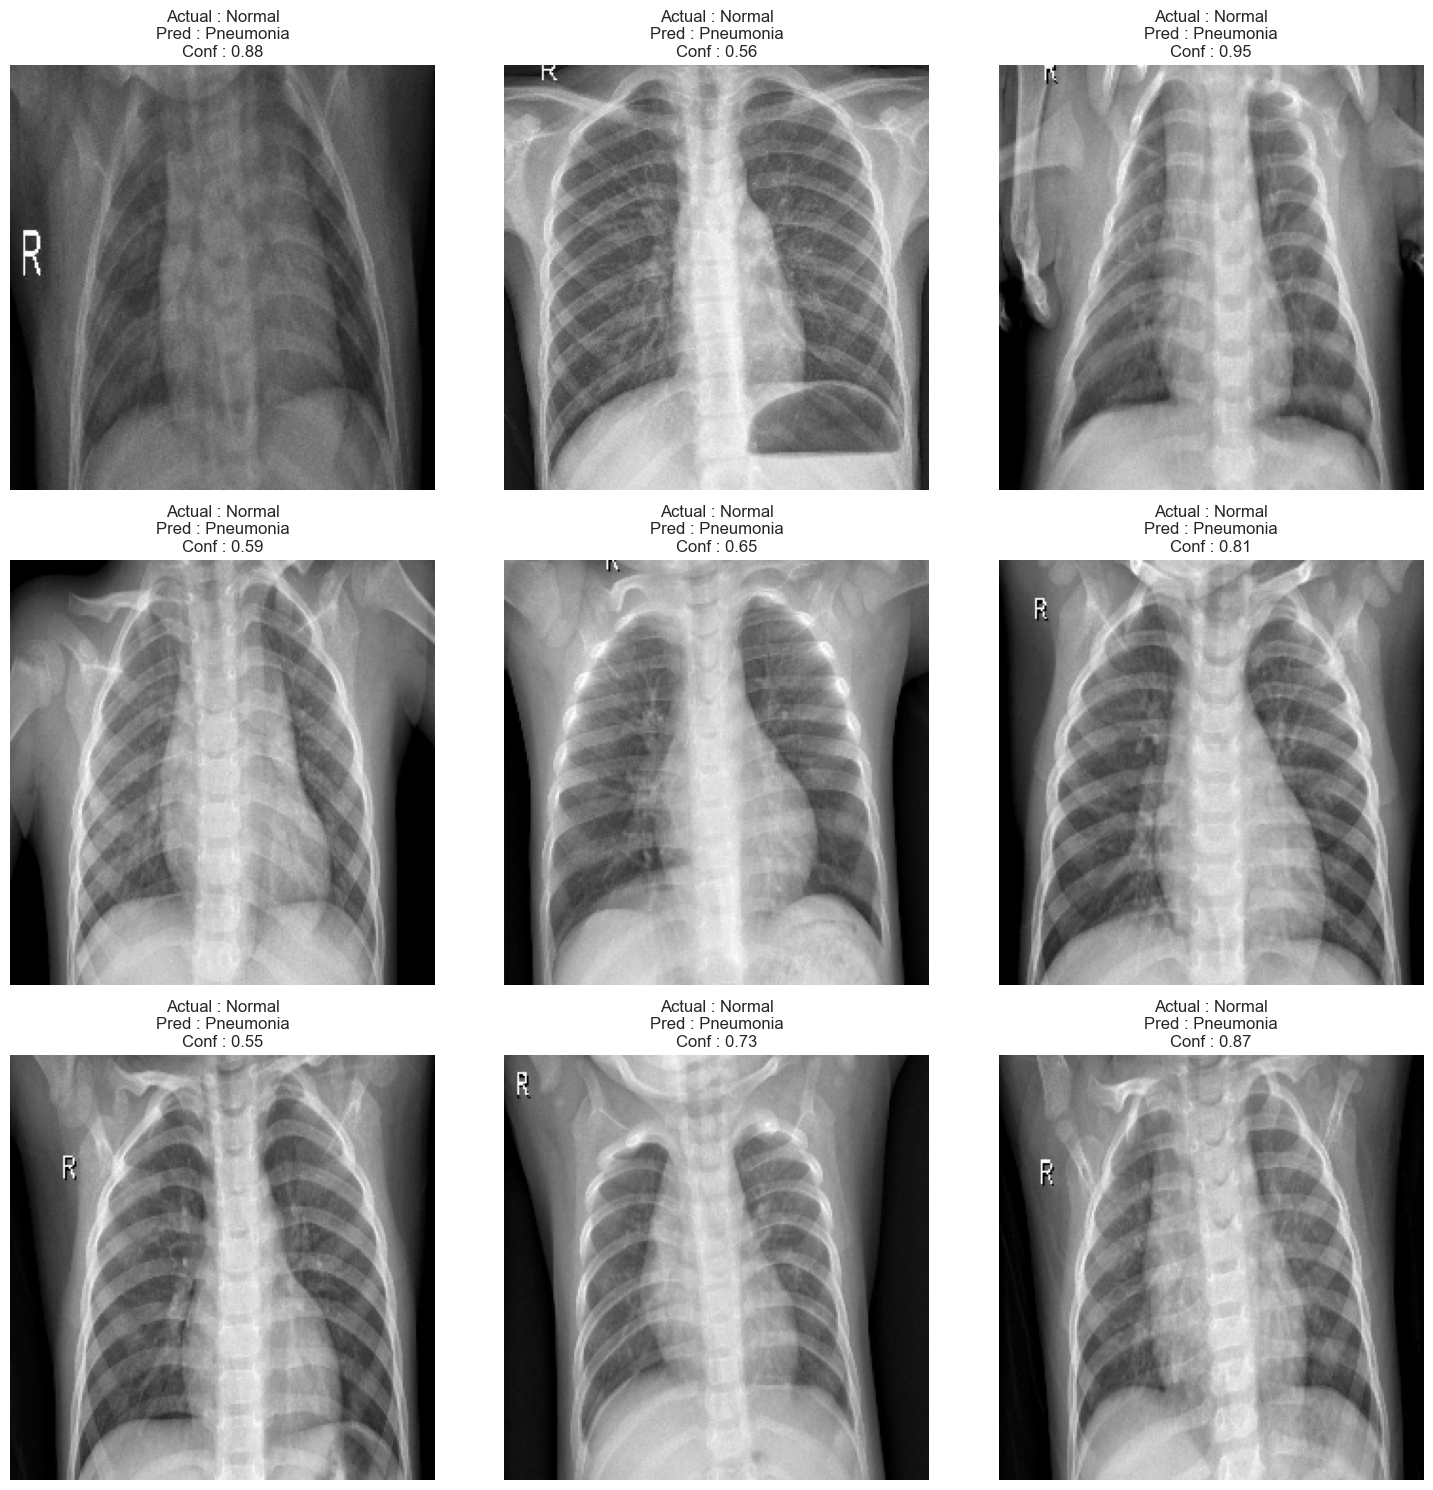

In [100]:
plt.figure(figsize=(15,15))

class_names = ["Normal", "Pneumonia"]

for i, idx in enumerate(misclassified[:9]):

    img_path = test_generator.filepaths[idx]

    img = image.load_img(
        img_path,
        target_size=IMAGE_SIZE
    )

    img_array = image.img_to_array(img)

    plt.subplot(3,3,i+1)

    plt.imshow(img)

    actual = class_names[true_labels[idx]]

    predicted = class_names[predictions[idx]]

    confidence = probabilities[idx][0]

    plt.title(
        f"Actual : {actual}\n"
        f"Pred : {predicted}\n"
        f"Conf : {confidence:.2f}"
    )

    plt.axis("off")

plt.tight_layout()

plt.savefig(
    RESULTS_DIR/"misclassified_images.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Discussion

The trained MobileNetV2 model demonstrates strong performance on the Chest X-ray dataset.

### Observations

- High recall indicates that most pneumonia cases were correctly identified.
- A small number of normal X-rays were incorrectly classified as pneumonia.
- This behavior is generally preferable in medical screening because missing pneumonia cases can have more serious consequences than additional follow-up examinations for healthy patients.

Overall, the model provides a strong balance between sensitivity and overall classification performance.

In [101]:
import shutil

shutil.move(
    MODEL_DIR / "checkpoint_best.keras",
    MODEL_DIR / "final_model.keras"
)

print("✅ Final model saved successfully!")

✅ Final model saved successfully!


In [102]:
print("Models")

print("-"*40)

for file in MODEL_DIR.iterdir():

    print(file.name)

Models
----------------------------------------
final_model.keras


In [103]:
print("Results")

print("-"*40)

for file in RESULTS_DIR.iterdir():

    print(file.name)

Results
----------------------------------------
classification_report.txt
history.json
metrics.csv
metrics.json
misclassified_images.png
roc_curve.png


In [104]:
print(train_generator.class_indices)

{'NORMAL': 0, 'PNEUMONIA': 1}
